# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі ПІСЛЯ, викликаючи `set_seed()`. Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [7]:
numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)
print("Рандомне число:", random.randint(1, 100))
random.shuffle(numbers)
print("Рандомно перемішаний масив: ", numbers)

set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ
# окремим генеруванням, не один раз на обидва

set_seed()
print("Рандомне число з зафіксованим seed:", random.randint(1, 100))

set_seed()
random.shuffle(numbers)
print("Рандомно перемішаний масив з зафіксованим seed: ", numbers)

Рандомне число: 76
Рандомно перемішаний масив:  [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]
Seed зафіксовано: 42
Рандомне число з зафіксованим seed: 82
Рандомно перемішаний масив з зафіксованим seed:  [8, 9, 2, 0, 1, 7, 6, 5, 4, 3]


За звичайних умов `random` для генерації псевдовипадковості початковими даними для алгоритму зчитує системний шум операційної системи, або ж поточний час. Коли ми використовуємо `set_seed()` замість цих початкових даних ми задаємо статичне число для алгоритму, а якщо початкові дані співпадають то алгоритм буде генерувати однаковий набір чисел.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [8]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [9]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [10]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [11]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(".ndim для identity", identity.ndim)
print(random_ints)
print(".ndim для random_ints", random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
.ndim для identity 2
[[6 3 7]
 [4 6 9]
 [2 6 7]]
.ndim для random_ints 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [12]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [13]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [14]:
df = pd.DataFrame({
    'student': ['Олена', 'Максим', 'Ірина', 'Андрій', 'Дмитро'],
    'score': [75, 85, 62, 90, 88]
}) # додай тут дані для DataFrame

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df['score'] > 80].sort_values(by='score', ascending=False)
print(top)


  student  score
3  Андрій     90
4  Дмитро     88
1  Максим     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [15]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"

df["grade"] = np.select(
    [
      df["score"] >= 90,
      df["score"] >= 75
    ],
    ['A', 'B'],
    default='C')
print(df)


  student  score grade
0   Олена     75     B
1  Максим     85     B
2   Ірина     62     C
3  Андрій     90     A
4  Дмитро     88     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [16]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t)
print(sevens_t)
print("\nФорма zeros_t: ", zeros_t.shape, "\nТип даних zeros_t", zeros_t.dtype)
print("\nФорма sevens_t: ", sevens_t.shape, "\nТип даних sevens_t", sevens_t.dtype)


tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[7, 7, 7],
        [7, 7, 7]])

Форма zeros_t:  torch.Size([2, 3]) 
Тип даних zeros_t torch.float32

Форма sevens_t:  torch.Size([2, 3]) 
Тип даних sevens_t torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [17]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [18]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print(random_t)

print("\nФорма from_list: ", from_list.shape, "\nТип даних from_list", from_list.dtype,
      "\nВимірність from_list:", from_list.ndim)

print("\nФорма random_t: ", random_t.shape, "\nТип даних random_t", random_t.dtype,
      "\nВимірність random_t:", random_t.ndim)


tensor([[1, 2],
        [3, 4]])
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])

Форма from_list:  torch.Size([2, 2]) 
Тип даних from_list torch.int64 
Вимірність from_list: 2

Форма random_t:  torch.Size([3, 3]) 
Тип даних random_t torch.float32 
Вимірність random_t: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [19]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

auto_grad = x.grad.item()
analytic_grad = 2 * n

print("Автоматичний градієнт:", auto_grad)
print("Аналітичний градієнт: ", analytic_grad)
print("Результати співпадають:", auto_grad == analytic_grad)

Автоматичний градієнт: 10.0
Аналітичний градієнт:  10.0
Результати співпадають: True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [20]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

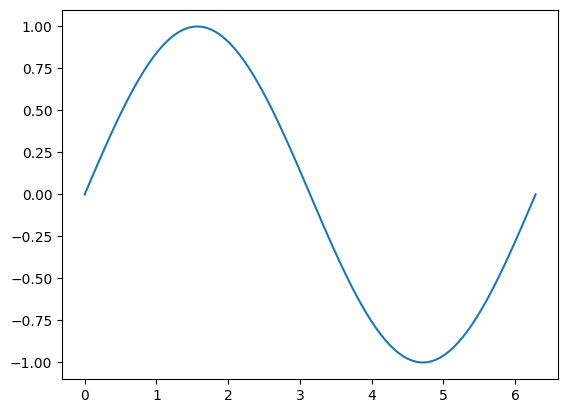

In [21]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

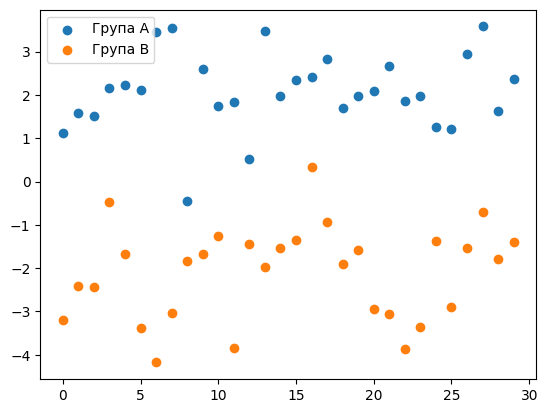

In [22]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()

plt.scatter(range(len(group_a)), group_a, color="C0", label="Група A")
plt.scatter(range(len(group_b)), group_b, color="C1", label="Група B")

plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [23]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

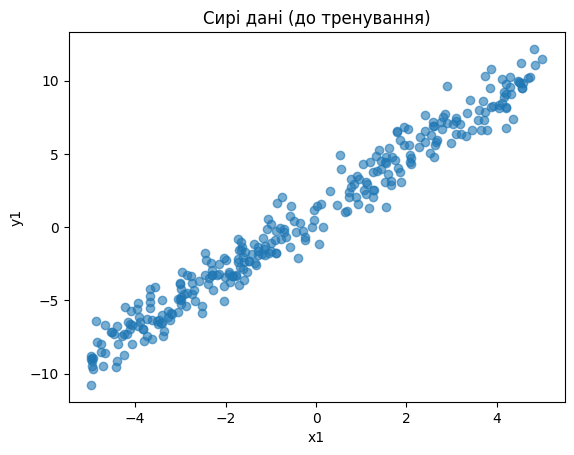

In [24]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1, y1, alpha=0.6)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [25]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15

indices = torch.randperm(TASK1_N)

x1_shuffled = x1[indices]
y1_shuffled = y1[indices]

train_size = int(0.70 * TASK1_N)
val_size = int(0.15 * TASK1_N)

x_train1, y_train1 = x1_shuffled[:train_size], y1_shuffled[:train_size]
x_val1, y_val1 = x1_shuffled[train_size:train_size + val_size], y1_shuffled[train_size:train_size + val_size]
x_test1, y_test1 = x1_shuffled[train_size + val_size:], y1_shuffled[train_size + val_size:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [26]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


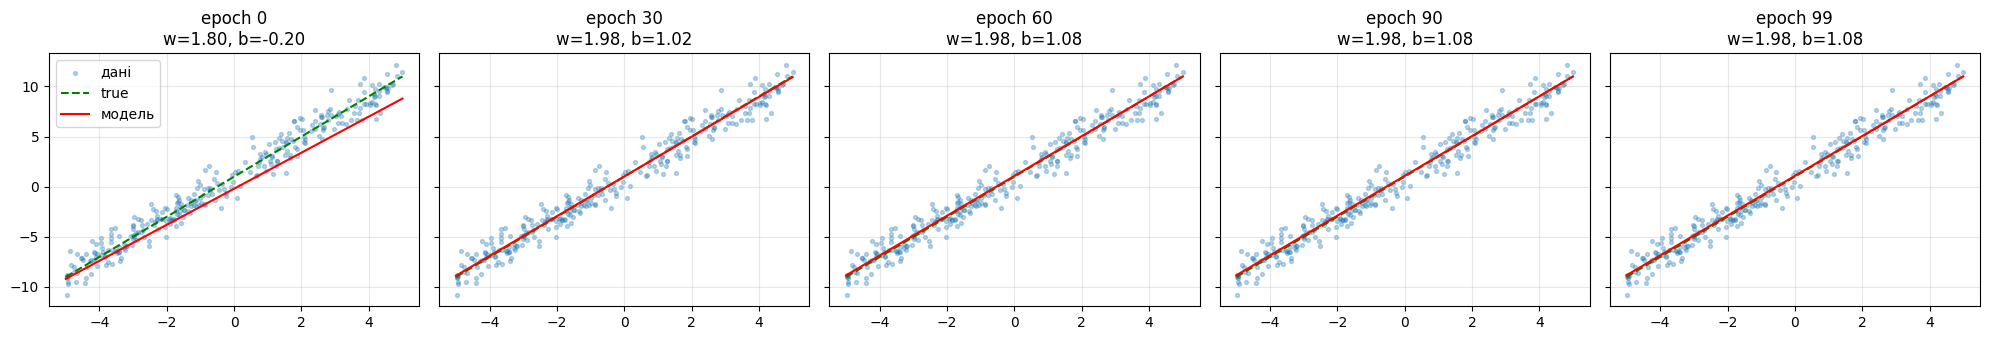

In [27]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

# Модель петлі залежності від вайбкодингу

### Опис сценарію
Чим більшу частку кодової бази проєкту згенеровано за допомогою ШІ, тим менше розробник тримає в голові контекст та внутрішні зв'язки системи. Через це будь-яка модифікація, рефакторинг змушує програміста ще частіше звертатися до нейромережі. Виникає замкнене коло залежності.

### Змінні:
* **$x$ (ознака / feature):** частка коду у проєкті, згенерована ШІ (від $0\%$ до $100\%$).
* **$y$ (цільова змінна / target):** кількість годин на тиждень, які розробник витрачає на промптинг та взаємодію з ШІ для підтримки проєкту.

### Математична залежність:
$$y = w \cdot x + b + \epsilon$$

### Обґрунтування параметрів:
* **`VIBE_TRUE_B = 2.0` (зсув / bias):** навіть якщо в проєкті $0\%$ ШІ-коду, сучасний інженер усе одно витрачає в середньому $\approx 2$ години на тиждень на ШІ (автокомпліт синтаксису, запити документації).
* **`VIBE_TRUE_W = 0.35` (вага / slope):** кожні додаткові $10\%$ коду від ШІ додають близько $3.5$ години на тиждень на підтримку та промптинг. При $80\%$ ШІ-коду розробник витрачає вже близько $2 + (0.35 \times 80) = 30$ годин на тиждень.
* **`VIBE_NOISE_STD = 3.0`:** випадковий розкид (індивідуальна швидкість мислення розробника, складність проєкту, вдалість промптів).

In [30]:
# Генерація даних

VIBE_TRUE_W = 0.35      # кожні 10% ШІ-коду додають ~3.5 години промптингу на тиждень
VIBE_TRUE_B = 2.0       # базові 2 години на тиждень на ШІ навіть при 0% ШІ-коду
VIBE_N = 500            # кількість розробників у вибірці
VIBE_NOISE_STD = 3.0    # природний розкид між людьми та проєктами

ai_code_pct = np.random.uniform(5, 95, size=VIBE_N)
noise = np.random.normal(0, VIBE_NOISE_STD, size=VIBE_N)
prompting_hours = VIBE_TRUE_W * ai_code_pct + VIBE_TRUE_B + noise

vibe_df = pd.DataFrame({
    "ai_code_pct": ai_code_pct,
    "prompting_hours": prompting_hours,
})

csv_path = os.path.join(ARTIFACT_DIR, "vibe_coding.csv")
vibe_df.to_csv(csv_path, index=False)
print("Дані збережено у:", csv_path)


Дані збережено у: /content/drive/MyDrive/ai_systems/lab1/vibe_coding.csv


In [33]:
# Завантажуємо CSV як pandas-таблицю

loaded_df = pd.read_csv(csv_path)
print("Розмір таблиці:", loaded_df.shape)
loaded_df.head()

Розмір таблиці: (500, 2)


,ai_code_pct,prompting_hours
0,27.577447,12.908625
1,21.590031,8.388646
2,12.278567,2.592665
3,43.548303,13.943838
4,66.964991,27.051045


In [34]:
x_raw = torch.tensor(loaded_df["ai_code_pct"].values, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(loaded_df["prompting_hours"].values, dtype=torch.float32).unsqueeze(1)

x_mean, x_std = x_raw.mean(), x_raw.std()
x = (x_raw - x_mean) / x_std

In [35]:
perm = torch.randperm(VIBE_N)
n_train = int(0.60 * VIBE_N)
n_val = int(0.20 * VIBE_N)

train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]

x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]

print(f"Розподіл вибірок: train={len(x_train)}, val={len(x_val)}, test={len(x_test)}")

Розподіл вибірок: train=300, val=100, test=100


In [36]:
model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line_raw = torch.linspace(0, 100, 100).unsqueeze(1)
x_line = (x_line_raw - x_mean) / x_std
snapshots = []

epochs = 100
for epoch in range(epochs):
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = loss_fn(y_pred, y_train)
    loss.backward()
    optimizer.step()

    if epoch % 30 == 0 or epoch == epochs - 1:
        with torch.no_grad():
            y_line_pred = model(x_line)
            val_loss = loss_fn(model(x_val), y_val).item()

        w_eff = model.weight.item() / x_std.item()
        b_eff = model.bias.item() - (model.weight.item() * x_mean.item() / x_std.item())
        snapshots.append((epoch, w_eff, b_eff, y_line_pred))

        print(f"Epoch {epoch:3d} | Train MSE: {loss.item():.4f} | Val MSE: {val_loss:.4f} | "
              f"w={w_eff:.4f} (true {VIBE_TRUE_W}) | b={b_eff:.4f} (true {VIBE_TRUE_B})")

Epoch   0 | Train MSE: 485.3203 | Val MSE: 415.5724 | w=0.0080 (true 0.35) | b=1.4203 (true 2.0)
Epoch  30 | Train MSE: 11.1829 | Val MSE: 10.4995 | w=0.3292 (true 0.35) | b=2.4194 (true 2.0)
Epoch  60 | Train MSE: 10.1447 | Val MSE: 9.7922 | w=0.3464 (true 0.35) | b=2.3274 (true 2.0)
Epoch  90 | Train MSE: 10.1424 | Val MSE: 9.7990 | w=0.3473 (true 0.35) | b=2.3177 (true 2.0)
Epoch  99 | Train MSE: 10.1424 | Val MSE: 9.7992 | w=0.3474 (true 0.35) | b=2.3173 (true 2.0)


In [37]:
with torch.no_grad():
    y_test_pred = model(x_test)
    test_mse = loss_fn(y_test_pred, y_test).item()
    test_mae = torch.mean(torch.abs(y_test_pred - y_test)).item()

print(f"\n--- Фінальні результати на Test вибірці ---")
print(f"Test MSE: {test_mse:.4f}")
print(f"Test MAE: {test_mae:.4f} годин")


--- Фінальні результати на Test вибірці ---
Test MSE: 7.6108
Test MAE: 2.2557 годин


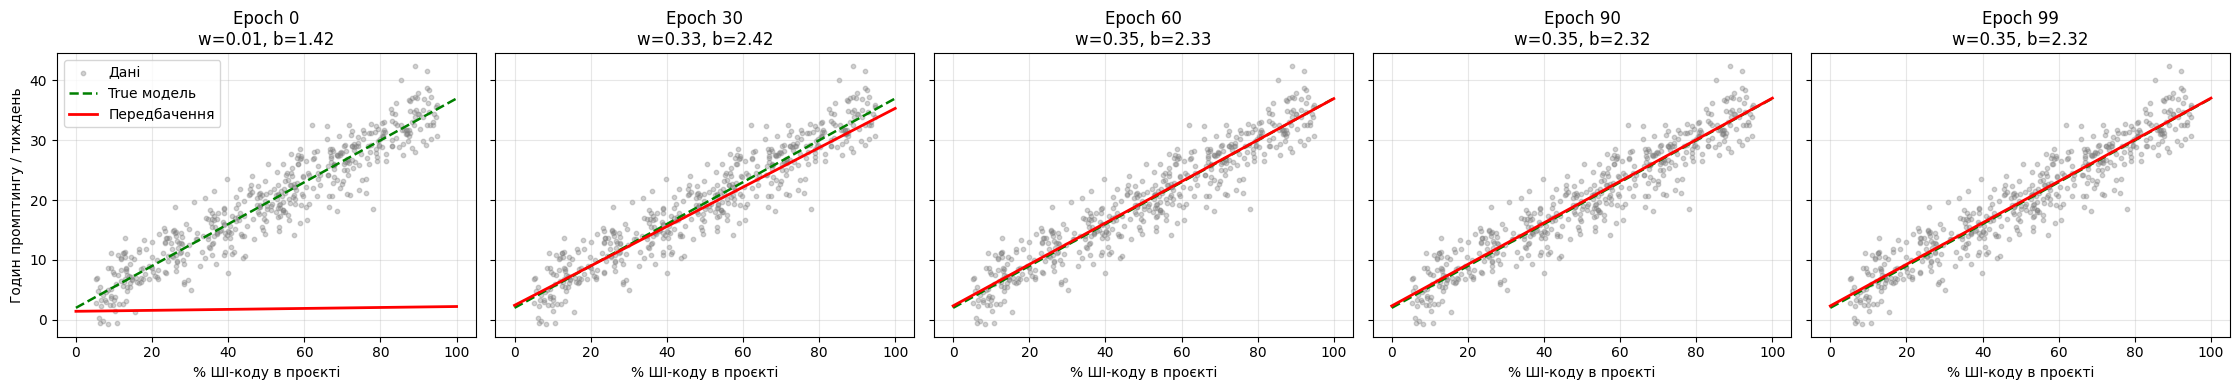

In [38]:
with torch.no_grad():
    y_line_true = VIBE_TRUE_W * x_line_raw + VIBE_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4.5 * len(snapshots), 4), sharey=True)

for ax, (epoch, w_eff, b_eff, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x_raw.numpy(), y.numpy(), s=10, alpha=0.35, color="gray", label="Дані")
    ax.plot(x_line_raw.numpy(), y_line_true.numpy(), "g--", linewidth=1.8, label="True модель")
    ax.plot(x_line_raw.numpy(), y_line_pred.numpy(), "r-", linewidth=2.0, label="Передбачення")
    ax.set_title(f"Epoch {epoch}\nw={w_eff:.2f}, b={b_eff:.2f}")
    ax.set_xlabel("% ШІ-коду в проєкті")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Годин промптингу / тиждень")
axes[0].legend()
plt.tight_layout()
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [39]:
model_path = os.path.join(ARTIFACT_DIR, "model.pt")

torch.save({
    "state_dict": model.state_dict(),
    "x_mean": x_mean.item(),
    "x_std": x_std.item(),
}, model_path)
print("Модель збережено у:", model_path)

Модель збережено у: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [40]:
!pip install -q gradio
import gradio as gr

checkpoint = torch.load(model_path, weights_only=False)

loaded_model = torch.nn.Linear(in_features=1, out_features=1)
loaded_model.load_state_dict(checkpoint["state_dict"])
loaded_model.eval()

loaded_x_mean = checkpoint["x_mean"]
loaded_x_std = checkpoint["x_std"]

def predict_prompting_hours(ai_code_pct: float) -> float:
    x_input = torch.tensor([[ai_code_pct]], dtype=torch.float32)
    x_input_norm = (x_input - loaded_x_mean) / loaded_x_std

    with torch.no_grad():
        hours_pred = loaded_model(x_input_norm)

    return max(0.0, round(hours_pred.item(), 1))

demo = gr.Interface(
    fn=predict_prompting_hours,
    inputs=gr.Slider(
        minimum=0,
        maximum=100,
        value=50,
        step=1,
        label="Частка коду, згенерована ШІ (%)"
    ),
    outputs=gr.Number(label="Прогнозований час на промптинг (годин/тиждень)"),
    title="Vibe Coding Loop: ШІ-код ➔ Години промптингу",
    description="Інтерактивна модель лінійної регресії. Пересувай повзунок частки ШІ-коду, щоб побачити, скільки годин на тиждень розробник витрачатиме на спілкування з ШІ через втрату ментальної моделі проєкту.",
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://43b723d2b4bca4e608.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```